Introduction

Feature selection is an important step in machine learning because the choice of input variables can influence model performance.

In this notebook, the features relevant to predicting menstrual cycle length are identified. The target variable is defined as Length_of_cycle, while the remaining selected variables are considered potential predictors.

Features that may introduce data leakage or unnecessary redundancy are excluded. The final set of features is prepared for the preprocessing stage.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../Dataset/menstrual_health_cleaned.csv"
)

print(df.head())

print("Dataset Shape:", df.shape)

   number_of_peak  Age  Length_of_cycle  Estimated_day_of_ovulution  \
0               3   18               27                          14   
1               4   18               25                          17   
2               2   19               30                          17   
3               3   19               28                          16   
4               2   19               35                          18   

   Length_of_Leutal_Phase  Length_of_menses Unusual_Bleeding  Weight   BMI  \
0                       9                 5               no    76.0  26.3   
1                      10                 6              yes    76.0  26.3   
2                      13                 4               no    56.0  21.9   
3                      14                 6               no    61.0  25.4   
4                      15                 5               no    55.0  21.5   

   Mean_of_length_of_cycle  Menses_score  
0                       30           4.0  
1                 

In [2]:
print(df.columns)

Index(['number_of_peak', 'Age', 'Length_of_cycle',
       'Estimated_day_of_ovulution', 'Length_of_Leutal_Phase',
       'Length_of_menses', 'Unusual_Bleeding', 'Weight', 'BMI',
       'Mean_of_length_of_cycle', 'Menses_score'],
      dtype='str')


In [3]:
#Define the target variable

target = "Length_of_cycle"

X = df.drop(columns=[
    "Length_of_cycle",
    "Mean_of_length_of_cycle",
    "Estimated_day_of_ovulution",
    "Weight"
])

y = df[target]

print("Independent Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Independent Features:
['number_of_peak', 'Age', 'Length_of_Leutal_Phase', 'Length_of_menses', 'Unusual_Bleeding', 'BMI', 'Menses_score']

Target Variable:
Length_of_cycle

Feature Shape: (81, 7)
Target Shape: (81,)


In [5]:
#Check feature correlations with the target

correlation = df.select_dtypes(
    include=np.number
).corr()["Length_of_cycle"].sort_values(
    ascending=False
)

print(correlation)

Length_of_cycle               1.000000
Mean_of_length_of_cycle       0.647733
Estimated_day_of_ovulution    0.312257
Length_of_Leutal_Phase        0.279700
number_of_peak                0.163817
Menses_score                 -0.020227
Length_of_menses             -0.032994
Weight                       -0.071218
Age                          -0.072735
BMI                          -0.148648
Name: Length_of_cycle, dtype: float64


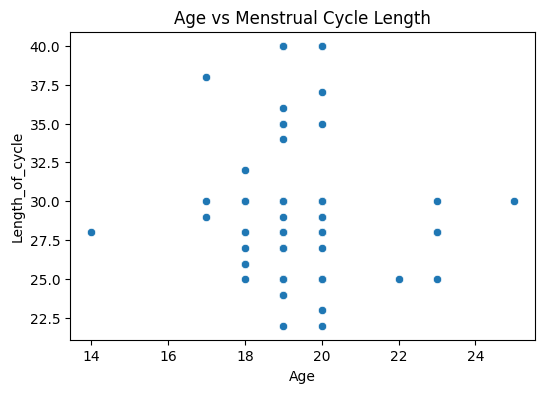

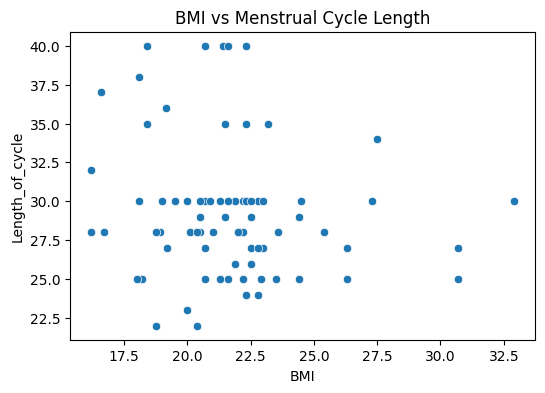

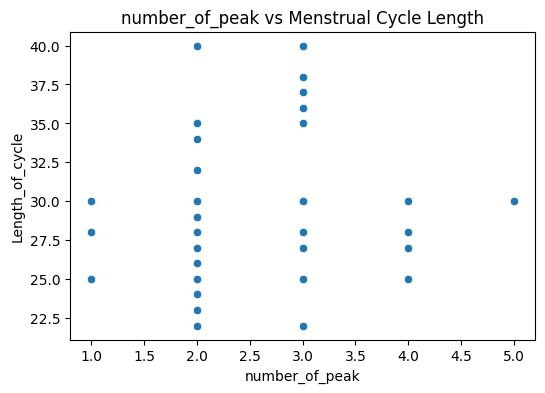

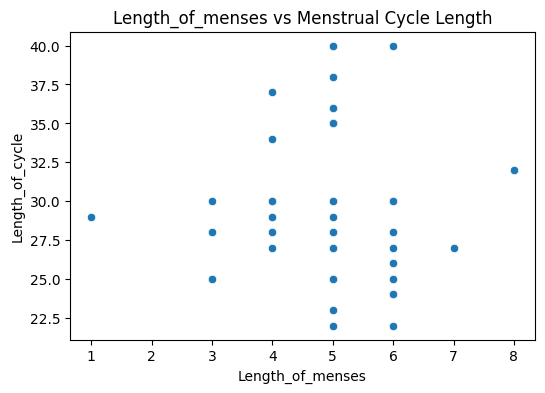

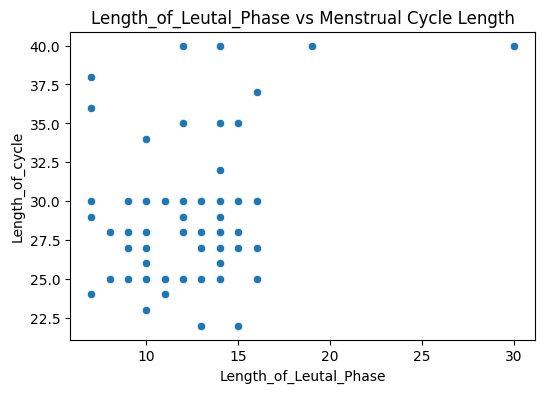

In [6]:
#Visualize target relationships

features = [
    "Age",
    "BMI",
    "number_of_peak",
    "Length_of_menses",
    "Length_of_Leutal_Phase"
]

for feature in features:

    plt.figure(figsize=(6,4))

    sns.scatterplot(
        x=df[feature],
        y=df["Length_of_cycle"]
    )

    plt.title(f"{feature} vs Menstrual Cycle Length")
    plt.show()

Conclusion

In this notebook, the target variable and independent features were identified.

A total of seven input features were selected for the prediction task: number of peak, age, luteal phase length, menstrual duration, unusual bleeding, BMI, and menses score.

Potentially redundant or unsuitable variables were excluded. The selected features will be used for data preprocessing and model development.